# Volatility Targeting on the Japanese Stock Market
**Author:** Silam Shrestha

**Question:** If we hold *less* when the market is wild and *more* when it is calm, do we get a smoother ride with similar return?

**Idea in one line:** position size = target volatility ÷ recent volatility.

**Data:** TOPIX ETF (ticker `1306.T`), which tracks the whole Japanese market.

## Step 1. Tools

In [1]:
!pip install yfinance -q
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yfinance as yf

## Step 2. Settings
- `TARGET_VOL = 0.10` means we aim for **10% yearly volatility**.
- `LOOKBACK = 20` uses the last **20 trading days** (about one month) to measure recent volatility.
- `MAX_LEVERAGE = 1.5` stops us borrowing too much when markets are very calm.
- `COST = 0.0005` is a 0.05% cost each time we change position size.

In [2]:
TICKER = "1306.T"
START, END = "2010-01-01", "2025-12-31"
TARGET_VOL, LOOKBACK, MAX_LEVERAGE, COST = 0.10, 20, 1.5, 0.0005

## Step 3. Download prices and compute daily returns

In [3]:
raw = yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)
px = raw["Close"]
if isinstance(px, pd.DataFrame):
    px = px.iloc[:, 0]
px = px.dropna()
if px.empty:
    raise RuntimeError("No data downloaded. Check internet and run again.")
ret = px.pct_change().dropna()
print(len(ret), "days from", ret.index[0].date(), "to", ret.index[-1].date())

3932 days from 2010-01-05 to 2025-12-30


## Step 3b. Clean the data: catch unadjusted stock splits
If a fund splits its units (for example 1 unit becomes 10), the price drops about 90% in one day. That is **not a real loss**, but if the data provider does not adjust for it, it looks like a crash.

We flag any day with a move bigger than ±20% (the TOPIX never moves that much in one day) and set that day's return to 0. Always check your data before trusting results.

In [4]:
suspicious = ret[ret.abs() > 0.20]
print("Suspicious days (likely unadjusted splits):")
print(suspicious)
ret = ret.where(ret.abs() <= 0.20, 0.0)
print()
print("After cleaning: largest daily move =", round(ret.abs().max(), 4))

Suspicious days (likely unadjusted splits):
Date
2015-01-05   -0.900624
Name: 1306.T, dtype: float64

After cleaning: largest daily move = 0.1681


## Step 4. Measure recent (realised) volatility
Realised volatility = standard deviation of the last 20 daily returns × √252 (to make it yearly).

We use `.shift(1)` so today's position only uses volatility known **up to yesterday**: no look-ahead bias.

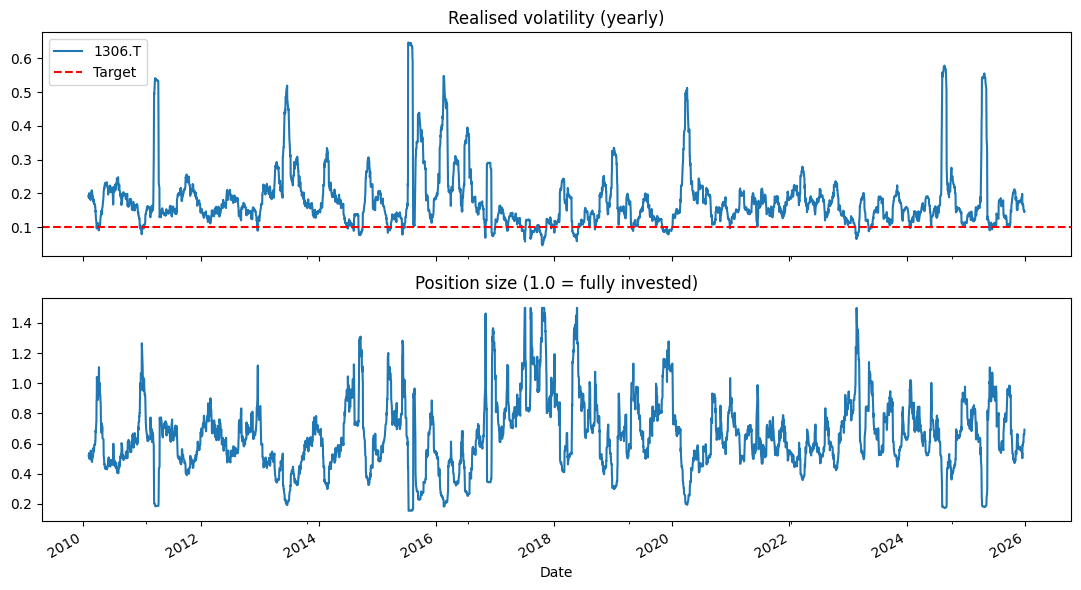

In [5]:
realised_vol = ret.rolling(LOOKBACK).std() * np.sqrt(252)
weight = (TARGET_VOL / realised_vol.shift(1)).clip(upper=MAX_LEVERAGE)

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
realised_vol.plot(ax=ax[0], title="Realised volatility (yearly)")
ax[0].axhline(TARGET_VOL, color="red", linestyle="--", label="Target")
ax[0].legend()
weight.plot(ax=ax[1], title="Position size (1.0 = fully invested)")
plt.tight_layout(); plt.show()

## Step 5. Strategy returns
- **Buy and hold:** always 100% invested.
- **Vol-targeted:** weight × market return, minus cost on weight changes.

In [6]:
turnover = weight.diff().abs().fillna(0)
vt_ret = (weight * ret - turnover * COST).dropna()
bh_ret = ret.loc[vt_ret.index]
def perf(r, periods=252):
    r = r.dropna()
    cum = (1 + r).cumprod()
    return pd.Series({
        "Annual return": r.mean() * periods,
        "Annual volatility": r.std() * np.sqrt(periods),
        "Sharpe": (r.mean() / r.std()) * np.sqrt(periods),
        "Max drawdown": (cum / cum.cummax() - 1).min(),
    })

pd.DataFrame({"Buy and hold": perf(bh_ret), "Vol-targeted": perf(vt_ret)})

,Buy and hold,Vol-targeted
Annual return,0.132556,0.064561
Annual volatility,0.198798,0.112637
Sharpe,0.666787,0.573181
Max drawdown,-0.326781,-0.203475


## Step 6. Compare growth and drawdowns

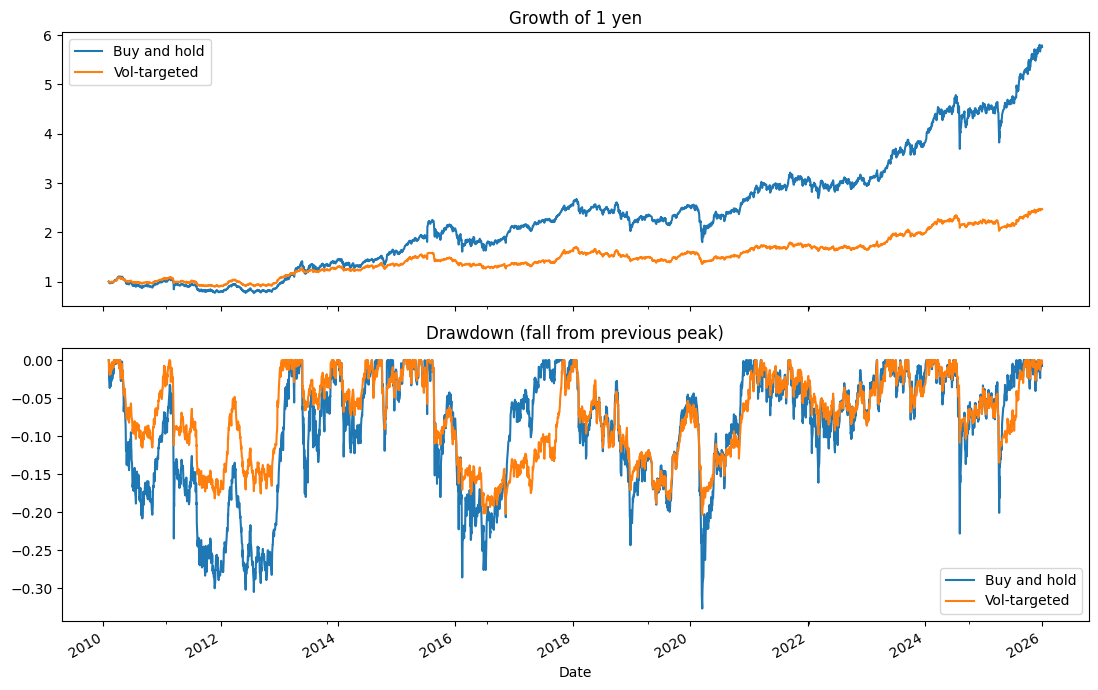

In [7]:
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for name, r in [("Buy and hold", bh_ret), ("Vol-targeted", vt_ret)]:
    cum = (1 + r).cumprod()
    cum.plot(ax=ax[0], label=name)
    (cum / cum.cummax() - 1).plot(ax=ax[1], label=name)
ax[0].set_title("Growth of 1 yen"); ax[0].legend()
ax[1].set_title("Drawdown (fall from previous peak)"); ax[1].legend()
plt.tight_layout(); plt.show()

## Step 7. Robustness: different lookbacks
A good result should not depend on one lucky setting.

In [8]:
rows = {}
for lb in [10, 20, 60, 120]:
    rv = ret.rolling(lb).std() * np.sqrt(252)
    w = (TARGET_VOL / rv.shift(1)).clip(upper=MAX_LEVERAGE)
    r = (w * ret - w.diff().abs().fillna(0) * COST).dropna()
    rows[f"{lb}-day lookback"] = perf(r)
pd.DataFrame(rows).T

,Annual return,Annual volatility,Sharpe,Max drawdown
10-day lookback,0.058574,0.118880,0.492716,-0.239292
20-day lookback,0.064561,0.112637,0.573181,-0.203475
60-day lookback,0.066424,0.110474,0.601265,-0.237999
120-day lookback,0.071474,0.109577,0.652274,-0.257852


## Step 8. Conclusions
1. **Volatility targeting cut risk a lot.** Annual volatility fell from 19.9% to 11.3%, and the maximum drawdown fell from −32.7% to −20.3%.
2. **It did not improve the Sharpe ratio.** Sharpe went from 0.67 (buy and hold) to 0.57. The strategy earned less (6.5% vs 13.3% a year) because it was usually less than fully invested, and cutting exposure after volatile periods sometimes meant missing the rebound.
3. **The result is stable across lookbacks.** Sharpe ranged from 0.49 (10 days) to 0.65 (120 days), always slightly below buy and hold, while drawdowns stayed between −20% and −26%. Longer lookbacks worked a little better, probably because they react less to short-lived spikes and trade less.

**Conclusion:** on Japanese equities in 2010–2025, volatility targeting worked as a **risk-control tool** (smoother returns, smaller drawdowns) but not as a return enhancer. This is consistent with research such as Moreira and Muir (2017), which finds that the benefits of volatility-managed portfolios vary across markets and periods.

**Data note:** the raw ETF data contained an unadjusted unit split on 5 January 2015, which appeared as a −90% day. Without the cleaning step, buy and hold showed a false −91% drawdown. After cleaning, the largest remaining daily move is 16.8%, which is still larger than the TOPIX index's biggest daily fall (about −12% on 5 August 2024), so the ETF data may contain another smaller error worth checking.

**Why it can work:** volatility clusters (calm days follow calm days, wild days follow wild days), and big crashes usually happen when volatility is already high.

**Limitations:** one market only; leverage above 1 needs borrowing; ignores financing costs; results depend on the crash periods in the sample (for example 2020).